In [ ]:
# install.packages('redux')

In [1]:
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(rliger)

source("formating.R")


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Package `rliger` has been updated massively since version 1.99.0, including the object structure which is not compatible with old versions.

We recommand you backup your old analysis before overwriting any existing result.

`readLiger()` is provided for reading an RDS file storing an old object and it converts the object to the up-to-date structure.

Loading required package: SingleCellExperiment

Loading required package: SummarizedExperiment

Loading required package: MatrixGenerics

Loading required package: matrixStats


Attaching package: ‘matrixStats’


The following object is masked from ‘package:dplyr’:

    count



Attaching package: ‘MatrixGenerics’


The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
  

In [ ]:
packageVersion("rliger")

In [2]:
datasets <- strsplit('CONTROL_1,CONTROL_2,CONTROL_3,HEALTHY_4,HEALTHY_5,DIABETIC_1,DIABETIC_2,DIABETIC_3,DIABETIC_4,DIABETIC_5,HEALTHY_6', ",")[[1]]
inputs <- strsplit('../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/control_1.h5ad,../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/control_2.h5ad,../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/control_3.h5ad,../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/healthy_4.h5ad,../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/healthy_5.h5ad,../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/diabetic_1.h5ad,../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/diabetic_2.h5ad,../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/diabetic_3.h5ad,../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/diabetic_4.h5ad,../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/diabetic_5.h5ad,../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/healthy_6.h5ad', ",")[[1]]
inputs
npcs <- 30
dims <- 30
batch_key <- 'batch'
default_assay <- "RNA"

[1] "../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/control_1.h5ad" 
 [2] "../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/control_2.h5ad" 
 [3] "../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/control_3.h5ad" 
 [4] "../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/healthy_4.h5ad" 
 [5] "../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/healthy_5.h5ad" 
 [6] "../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/diabetic_1.h5ad"
 [7] "../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/diabetic_2.h5ad"
 [8] "../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/diabetic_3.h5ad"
 [9] "../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/diabetic_4.h5ad"
[10] "../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/diabetic_5.h5ad"
[11] "../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/healthy_6.h5ad"

In [3]:
srats.list <- list()
for (i in 1:length(inputs)) {
  srats.list[[datasets[i]]] <- LoadSeurat(inputs[i], project = datasets[i])
  srats.list[[datasets[i]]]@meta.data[batch_key] <- datasets[i]
  if(!params$default_assay %in% names(x = srats.list[[datasets[i]]])) stop(paste("RNA", "does not exist."))
  DefaultAssay(object = srats.list[[datasets[i]]]) <- default_assay
  print(paste("Seurat object for '", datasets[datasets[i]], "' is loaded and default assay is set to", params$default_assay, "."))
}
names(srats.list) <-datasets
assay_names <- names(srats.list[[datasets[1]]]@assays)

X -> counts

Adding AnnData layers to Seurat assays

Adding AnnData layers to Seurat assays

Adding AnnData layers to Seurat assays

Warning message:
“Keys should be one or more alphanumeric characters followed by an underscore, setting key from raw_counts_ to rawcounts_”
Adding AnnData layers to Seurat assays

Adding AnnData embeddings to Seurat assays

Adding AnnData embeddings to Seurat assays

Adding AnnData embeddings to Seurat assays

Adding AnnData embeddings to Seurat assays

Adding AnnData embeddings to Seurat assays

X -> counts

X -> counts

Adding AnnData layers to Seurat assays

Adding AnnData layers to Seurat assays

Adding AnnData layers to Seurat assays

Warning message:
“Keys should be one or more alphanumeric characters followed by an underscore, setting key from raw_counts_ to rawcounts_”
Adding AnnData layers to Seurat assays

Adding AnnData embeddings to Seurat assays

Adding AnnData embeddings to Seurat assays

Adding AnnData embeddings to Seurat assays

Adding An

In [4]:
options(future.globals.maxSize = 50 * 1024^3)
for (i in 1:length(inputs)) {
    if(params$default_assay == 'RNA') srats.list[[datasets[i]]] <- SCTransform(srats.list[[datasets[i]]], verbose = F)
    srats.list[[datasets[i]]] <- FindVariableFeatures(srats.list[[datasets[i]]], selection.method = "vst", nfeatures = 2000, verbose = F) 
}

srats.features <- SelectIntegrationFeatures(object.list = srats.list, nfeatures = 2000) 
srats.list <- PrepSCTIntegration(object.list = srats.list, anchor.features = srats.features, verbose = FALSE) 
srats.anchors <- FindIntegrationAnchors(object.list = srats.list, normalization.method = "SCT", anchor.features = srats.features)
srats.integrated <- IntegrateData(anchorset = srats.anchors, normalization.method = "SCT")

Finding all pairwise anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 5837 anchors

Filtering anchors

	Retained 5352 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 8357 anchors

Filtering anchors

	Retained 7339 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 7634 anchors

Filtering anchors

	Retained 6465 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 6601 anchors

Filtering anchors

	Retained 5912 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 5495 anchors

Filtering anchors

	Retained 4753 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 7530 anchors

Filtering anchors

	Retained 6657 anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 6795 anchors

Filtering anchors

	Retained 6170 anchors

Running CCA

Merging objects

Fi

In [ ]:
DefaultAssay(srats.integrated) <- "integrated"
srats.integrated <- ScaleData(srats.integrated, verbose = F)
srats.integrated <- RunPCA(object = srats.integrated, verbose = FALSE) 

In [ ]:
srats.integrated <- FindNeighbors(srats.integrated, dims = 1:dims, k.param = 10, verbose = F)
srats.integrated <- FindClusters(srats.integrated, verbose = F, resolution = 0.8)

In [ ]:
srats.integrated <- subset(srats.integrated, features = VariableFeatures(srats.integrated)) # Keep only HVGs to make the dimensions match accross counts, data and scale.data
adata <- SeuratToAnndata(srats.integrated, main_layer="scale.data", transfer_layers="data", assay="integrated", transfer_assay="RNA", transfer_assay_obsm="counts")

In [5]:
srats.integrated

An object of class Seurat 
4859 features across 35703 samples within 3 assays 
Active assay: integrated (1097 features, 1097 variable features)
 2 layers present: data, scale.data
 2 other assays present: RNA, SCT

In [6]:
DefaultAssay(srats.integrated) <- "integrated"
srats.integrated <- ScaleData(srats.integrated, verbose = F)
srats.integrated <- RunPCA(object = srats.integrated, verbose = FALSE) 

In [7]:
srats.integrated <- FindNeighbors(srats.integrated, dims = 1:dims, k.param = 10, verbose = F)
srats.integrated <- FindClusters(srats.integrated, verbose = F, resolution = 0.8)

In [9]:
srats.integrated <- subset(srats.integrated, features = VariableFeatures(srats.integrated)) # Keep only HVGs to make the dimensions match accross counts, data and scale.data

In [10]:
dim(srats.integrated[['RNA']]$data)

[1]  1097 35703

In [11]:
dim(srats.integrated[['RNA']]$counts)

[1]  1097 35703

In [12]:
dim(srats.integrated[['SCT']]$data)

[1]  1097 35703

In [13]:
dim(srats.integrated[['SCT']]$counts)

[1]  1097 35703

In [14]:
dim(srats.integrated[['integrated']]$scale.data)

[1]  1097 35703

In [17]:
adata <- SeuratToAnndata1(srats.integrated, out_file='../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/seurat.h5ad', main_layer="scale.data", transfer_layers="data", assay="integrated", transfer_assay="RNA", transfer_assay_obsm="counts")
adata

Warning message in `[<-`(`*tmp*`, paste0(transfer_assay, "_", layer), value = Matrix::t(mat)):
“implicit list embedding of S4 objects is deprecated”


AnnData object with n_obs × n_vars = 35703 × 1097
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'soma_joinid', 'dataset_id', 'assay', 'assay_ontology_term_id', 'cell_type', 'cell_type_ontology_term_id', 'development_stage', 'development_stage_ontology_term_id', 'disease', 'disease_ontology_term_id', 'donor_id', 'is_primary_data', 'self_reported_ethnicity', 'self_reported_ethnicity_ontology_term_id', 'sex', 'sex_ontology_term_id', 'suspension_type', 'tissue', 'tissue_ontology_term_id', 'tissue_general', 'tissue_general_ontology_term_id', 'nFeatures_RNA', 'batch', 'size_factors', 'nFeatures_RNA_by_counts', 'log1p_nFeatures_RNA_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'doublet_score', 'predicted_doublet', 'clf_doublet', 'clf_score', 'leiden', 'lou

In [10]:
srats.integrated[['RNA']]$data

  [[ suppressing 32 column names ‘0’, ‘1’, ‘2’ ... ]]



2000 x 35703 sparse Matrix of class "dgCMatrix"
                                                                             
A2M                 .   .  .  .   .   .  1  .   .  1  .  .  .  .  .   .  .  .
AADACL2-AS1         .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
AARD                .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
AP001053.11         .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
ABCA8               .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
ABCB1               .   .  .  .   .   2  .  3   .  1  .  .  .  .  .   .  .  .
ABCB5               .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
ABCC4               .   .  .  .   .   7  .  .   .  6  . 12  4  .  .   .  1  .
ABCC8               .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
ABCC9               .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
ABCG1               .   .  .  .   .   .  .  .   .  .  .  .  .  6  .   1  .  .
ABCG2           

In [15]:
assay_names <- names(srats.integrated@assays)
assay_names

[1] "RNA"        "SCT"        "integrated"

In [16]:
srats.integrated[['integrated']]$data

  [[ suppressing 32 column names ‘0’, ‘1’, ‘2’ ... ]]



1097 x 35703 sparse Matrix of class "dgCMatrix"
                                                                      
SLC12A3         -1.671650566 -1.6417604984 -1.6507409023 -1.5840122380
SLC8A1          -1.657369620 -1.3863770612 -1.3893548168 -1.5268520857
PTPRQ           -0.512566646 -0.5676478946 -0.5098800890 -0.4653362064
SLC26A7         -1.022554882 -1.0877590503  0.8561491593 -0.8538583420
CLNK            -0.934140293 -0.8653276274 -0.9174570887 -0.8124796215
PTPRO           -0.522986957 -0.5184737102 -0.7370043424 -0.3695263840
SLC12A1         -1.385392251 12.2163162892 11.0975359778 -1.2771524158
EMCN            -0.462852514 -0.7270783367 -0.5336905324 -0.4311138219
SNTG1           -0.654165080 -0.5556107542 -0.5752949838 -0.7736199906
SLC26A4         -0.156202924 -0.2141701888 -0.1192556982 -0.1393175319
GPC5            -1.134848056  2.6862834734 10.0916928924 -0.9570516152
GPR116          -0.787209228 -0.8968837541 -0.8435782603 -0.6869494543
LDB2            -0.441109107 

In [17]:
srats.integrated[['integrated']]$scale.data

,0,1,2,3,4,5,6,7,8,9,⋯,39161,39162,39163,39165,39166,39167,39168,39171,39172,39174
SLC12A3,-1.74015863,-1.71026856,-1.71924896,-1.6525203,1.8868536,-1.7729401,10.00000000,-0.56046867,-1.74806744,-1.72637243,⋯,-1.01014623,-1.85455312,-1.50678007,-1.54387751,-1.54298946,-1.63688547,-1.91537714,-1.98268480,-1.48987944,-1.94867436
SLC8A1,-1.67288254,-1.40188999,-1.40486774,-1.5423650,10.0000000,-1.6005759,-0.86365597,-0.24519436,-1.60256975,-1.46320500,⋯,-1.35426168,-1.60188749,1.76949302,-1.25525134,-0.98185605,-1.11566494,-0.80572358,-1.48728067,-1.65088199,-1.96588263
PTPRQ,-0.42164719,-0.47672844,-0.41896064,-0.3744168,-0.3828741,-0.3833700,-0.39328278,-0.31207315,-0.48235799,-0.28832716,⋯,1.98975850,-0.74000601,-0.71404316,-0.43220735,-0.55580067,-0.55440619,0.70088542,-0.70001827,0.55531264,-0.57277609
SLC26A7,-0.65134510,-0.71654927,1.22735894,-0.4826486,-0.5970510,-0.6427510,-0.57145358,-0.73702706,-0.19143838,-0.65073162,⋯,-0.69232043,0.46390364,-0.64815951,-0.15795097,-0.66567245,-0.82913883,-0.87498660,-0.27660028,-0.96124938,-0.51536765
CLNK,-0.62775956,-0.55894689,-0.61107636,-0.5060989,-0.4185449,-0.5977801,-0.47419036,-0.47716514,-0.60177552,-0.63133414,⋯,-0.57450398,-0.71856809,-1.09195135,-0.85264254,-0.92600944,-0.77257423,-1.01295915,-0.79956830,-0.78961659,-0.48505490
PTPRO,-0.41736849,-0.41285524,-0.63138588,-0.2639079,-0.3747547,-0.4009080,-0.31714504,-0.18554973,-0.18690391,-0.33390319,⋯,-0.37966544,-0.55354922,-0.55152092,-0.39885822,-0.40514136,0.20827855,-0.63713262,0.05445341,-0.50378520,-0.66557325
SLC12A1,-2.22183776,10.00000000,10.00000000,-2.1135979,-2.1887027,-2.2511005,-2.15227236,3.91903418,10.00000000,-2.03297590,⋯,2.50364034,-2.09863436,-1.64941283,-1.75307227,8.43981334,-2.45148475,-2.42302147,-2.42585527,-1.56128743,-2.42134492
EMCN,-0.42964810,-0.69387393,-0.50048612,-0.3979094,-0.3828913,-0.4674438,-0.30960189,-0.53294660,-0.24892661,0.45419682,⋯,-0.48761881,0.25449884,0.99925669,-0.38824076,0.22147609,-0.04927526,-0.54683151,-0.70786619,0.47901798,-0.05619743
SNTG1,-0.65968740,-0.56113308,-0.58081731,-0.7791423,-0.1193130,-0.5466372,-0.58534966,-0.26626707,-0.61289456,0.76708598,⋯,-1.02142895,-0.33410990,10.00000000,-1.08579050,-0.66146557,-0.33906199,-0.84582457,-0.38448312,-1.60332219,0.41835746
SLC26A4,-0.16270208,-0.22066934,-0.12575485,-0.1458167,-0.2271703,-0.2847782,-0.38154122,-0.32119544,-0.25419357,-0.26730046,⋯,-0.15775364,-0.68077059,-0.45674824,-0.33274489,-0.41959668,0.03809965,-0.83756388,-0.50687731,-0.41159157,-0.47363892


In [26]:
srat <- srats.list[[datasets[1]]]
srat

An object of class Seurat 
3469 features across 3397 samples within 2 assays 
Active assay: SCT (1469 features, 1469 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: RNA

In [28]:
assay_names <- names(srats.list[[datasets[1]]]@assays)
assay_names

[1] "RNA" "SCT"

In [29]:
'SCT' %in% assay_names

[1] TRUE

In [31]:
DefaultAssay(srats.integrated) <- "integrated"
srats.integrated <- ScaleData(srats.integrated, verbose = F)
srats.integrated <- RunPCA(object = srats.integrated, verbose = FALSE) 
srats.integrated <- RunUMAP(object = srats.integrated, dims = 1:30) 
srats.integrated <- FindNeighbors(srats.integrated, dims = 1:dims, k.param = 10, verbose = F)
srats.integrated <- FindClusters(srats.integrated, verbose = F, resolution = 0.5)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
18:24:50 UMAP embedding parameters a = 0.9922 b = 1.112

18:24:50 Read 35703 rows and found 30 numeric columns

18:24:50 Using Annoy for neighbor search, n_neighbors = 30

18:24:50 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

18:24:57 Writing NN index file to temp file /tmp/RtmpqusPJg/file3464bbee6e9

18:24:57 Searching Annoy index using 1 thread, search_k = 3000

18:25:13 Annoy recall = 100%

18:25:15 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors =

In [33]:
obsm <- NULL
reductions <- names(srats.integrated@reductions)
if (length(reductions) > 0) {
    obsm <- sapply(
    reductions,
    function(name) as.matrix(Seurat::Embeddings(srats.integrated, reduction=name)),
    simplify = FALSE
    )
    names(obsm) <- paste0("X_", tolower(names(srats.integrated@reductions)))
}

obsm

,PC_1,PC_2,PC_3,PC_4,PC_5,PC_6,PC_7,PC_8,PC_9,PC_10,⋯,PC_41,PC_42,PC_43,PC_44,PC_45,PC_46,PC_47,PC_48,PC_49,PC_50
0,11.908617,-1.7298735,-1.1642703,-0.23089058,-2.08864722,0.262876470,-0.16751812,-1.48724310,-1.131222184,0.159929765,⋯,-0.5401559329,-0.74556959,0.36729127,-0.81030214,0.47082881,0.49487120,0.25558856,0.60607478,0.82958450,0.64273898
1,-3.916403,3.6033506,-1.3876854,3.80969563,1.17921433,-5.737195060,-5.56189888,-0.05876866,-0.262567344,-0.228376512,⋯,1.3387055566,0.12793379,-0.62042452,1.27640172,-0.96113531,-0.17990861,-0.66842025,-0.01880195,1.59685703,-0.11139631
2,-4.638674,4.6792541,-1.7392794,3.80096086,-0.03562563,-6.702846556,-4.40233047,0.48173604,-0.839940802,0.068256059,⋯,-0.0919454468,-0.04833035,0.06789006,-1.25291653,0.14228484,-0.37619217,0.18412657,-0.50488490,-0.81678699,-0.16357959
3,8.800432,-0.9720108,-0.5770428,-0.60524376,-1.50479760,0.663604455,0.08412457,-1.85863647,-0.260969030,0.395488891,⋯,0.0003479853,-1.15808082,-1.53669032,-0.20039009,1.18762485,-1.07734585,-0.59878045,-0.34497705,0.40130355,-0.24021010
4,-2.794491,3.1599633,-0.8056852,0.34701136,-1.12743705,3.751663810,1.04141992,-0.10966053,-0.054508276,-0.070984603,⋯,0.5636272762,-0.49479300,0.09396198,-0.18511818,0.59798884,0.17935296,0.03784144,0.26486287,-0.45673650,-0.29028682
5,12.896062,-2.1965337,-0.5310485,-0.04618621,-0.95818813,-0.005967787,-0.25990016,-0.34151783,-0.001834497,0.220071593,⋯,0.8760587543,-0.30001868,-0.16894138,-1.08656412,-1.01710359,-0.25919033,-0.93137015,0.43734863,2.02197279,-1.63828654
6,-3.867720,3.6913423,-1.8575892,2.64045290,-3.25299045,-0.418910322,6.85279911,0.43291111,0.237268612,0.120787464,⋯,-1.6289858869,0.88132118,0.32216155,-0.19356129,-0.10651970,0.28320680,1.14992783,-0.69660302,0.65802458,1.25529033
7,-3.762356,3.3473148,-1.3425854,4.15279134,1.53542328,-2.442356407,-3.25855572,0.94317466,-0.611347628,0.122257675,⋯,-1.1273610292,0.62468277,0.34874910,0.20426623,-0.31227143,-0.01782017,0.33233311,0.28093454,0.40800756,0.61504258
8,-3.492507,4.0105179,-2.2494654,4.60603936,-0.62516297,-6.863698590,-3.94635765,0.03770755,-0.034256341,1.304212486,⋯,-0.6725448114,1.04840895,-1.08646219,-0.25592822,-2.49489181,0.02536999,-0.66718006,-0.67089587,-0.17015294,-0.15941706
9,9.542972,-4.1033419,-2.3489387,-0.51768059,-2.43431077,0.202335280,-0.35602285,-0.88900376,-1.943409060,-0.206965966,⋯,-0.6051037508,0.47531704,0.33960426,-0.12194308,0.86433753,0.55590884,0.95240770,-0.05863747,-1.96603238,2.01860850


In [35]:
mat <- Seurat::GetAssayData(object=srats.integrated, assay="SCT", layer="data")
obsm["SCT_data"] <- Matrix::t(mat)
obsm

Warning message in `[<-`(`*tmp*`, "SCT_data", value = new("dgCMatrix", i = c(6L, :
“implicit list embedding of S4 objects is deprecated”
  [[ suppressing 32 column names ‘A2M’, ‘AADACL2-AS1’, ‘ABCA8’ ... ]]

  [[ suppressing 32 column names ‘A2M’, ‘AADACL2-AS1’, ‘ABCA8’ ... ]]

  [[ suppressing 32 column names ‘A2M’, ‘AADACL2-AS1’, ‘ABCA8’ ... ]]



$X_pca
               PC_1          PC_2          PC_3          PC_4          PC_5
0      11.908617272  -1.729873482 -1.164270e+00 -2.308906e-01 -2.088647e+00
1      -3.916403279   3.603350567 -1.387685e+00  3.809696e+00  1.179214e+00
2      -4.638673602   4.679254117 -1.739279e+00  3.800961e+00 -3.562563e-02
3       8.800432432  -0.972010795 -5.770428e-01 -6.052438e-01 -1.504798e+00
4      -2.794490640   3.159963284 -8.056852e-01  3.470114e-01 -1.127437e+00
5      12.896061632  -2.196533716 -5.310485e-01 -4.618621e-02 -9.581881e-01
6      -3.867719749   3.691342342 -1.857589e+00  2.640453e+00 -3.252990e+00
7      -3.762355903   3.347314778 -1.342585e+00  4.152791e+00  1.535423e+00
8      -3.492506700   4.010517898 -2.249465e+00  4.606039e+00 -6.251630e-01
9       9.542971848  -4.103341933 -2.348939e+00 -5.176806e-01 -2.434311e+00
10     -3.365816074   4.328769202 -1.549681e+00  4.721434e+00  5.306516e-01
11     -3.451324647   4.351022122 -1.743113e+00 -1.943342e+01  1.462729e+00
12   

In [36]:
names(obsm)

[1] "X_pca"    "X_umap"   "SCT_data"

In [11]:
srats.integrated[['SCT']]@data

  [[ suppressing 32 column names ‘0’, ‘1’, ‘2’ ... ]]



1762 x 35703 sparse Matrix of class "dgCMatrix"
                                                                          
A2M             .        .         .         .         .         .        
AADACL2-AS1     .        .         .         .         .         .        
ABCA8           .        .         .         .         .         .        
ABCB1           .        .         .         .         .         0.6931472
ABCB5           .        .         .         .         .         .        
ABCC4           .        .         .         .         .         1.6094379
ABCC8           .        .         .         .         .         .        
ABCC9           .        .         .         .         .         .        
ABCG1           .        .         .         .         .         .        
ABCG2           .        .         .         .         .         1.0986123
ABI3BP          1.098612 .         .         .         .         .        
ABLIM2          .        .         .         .      

In [16]:
SeuratToAnndata1 <- function(obj, out_file=NULL, assay="RNA", main_layer="scale.data", transfer_layers="counts", transfer_assay=NULL, transfer_assay_obsm=NULL, drop_single_values=FALSE, drop_na_values=TRUE) {
    # print("inside s to a")
    # print(out_file)
    main_layer <- match.arg(main_layer, c("data", "counts", "scale.data"))
    transfer_layers <- transfer_layers[
        transfer_layers %in% c("data", "counts", "scale.data")
    ]
    transfer_layers <- transfer_layers[transfer_layers != main_layer]

    if (compareVersion(as.character(obj@version), "3.0.0") < 0) {
        obj <- Seurat::UpdateSeuratObject(object=obj)
    }

    X <- Seurat::GetAssayData(object=obj, assay=assay, layer=main_layer)

    # Change the names of metadata to AnnData naming convention
    if(paste0("nCount_", assay) %in% names(obj@meta.data)) names(obj@meta.data)[names(obj@meta.data) ==paste0("nCount_", assay)] <-"n_counts"
    if(paste0("nFeature_", assay) %in% names(obj@meta.data)) names(obj@meta.data)[names(obj@meta.data) ==paste0("nFeature_", assay)] <-"n_genes"
    if("percent.mt" %in% names(obj@meta.data)) names(obj@meta.data)[names(obj@meta.data) =="percent.mt"] <-"pct_counts_mt"
    if("percent.rb" %in% names(obj@meta.data)) names(obj@meta.data)[names(obj@meta.data) =="percent.rb"] <-"pct_counts_rb"
    if("percent.hb" %in% names(obj@meta.data)) names(obj@meta.data)[names(obj@meta.data) =="percent.hb"] <-"pct_counts_hb"
    # if("seurat_clusters" %in% names(obj@meta.data)) names(obj@meta.data)[names(obj@meta.data) =="seurat_clusters"] <-"leiden"

    obs <- .regularise_df(obj@meta.data, drop_single_values=drop_single_values, drop_na_values=drop_na_values)

    var <- .regularise_df(Seurat::GetAssay(obj, assay=assay)@meta.features, drop_single_values=drop_single_values, drop_na_values=drop_na_values)

    colnames(var) <- sub("vst.variable", "highly_variable", colnames(var))

    obsm <- NULL
    reductions <- names(obj@reductions)
    tryCatch({
        if (length(reductions) > 0) {
            obsm <- sapply(
            reductions,
            function(name) as.matrix(Seurat::Embeddings(obj, reduction=name)),
            simplify = FALSE
            )
            names(obsm) <- paste0("X_", tolower(names(obj@reductions)))
        }
    }, error = function(e) {
        print(paste0("An error happened when saving obsm, skipped: ", e$message))
    }) 

    layers <- list()
    for (layer in transfer_layers) {
        mat <- Seurat::GetAssayData(object=obj, assay=assay, layer=layer)
        if (all(dim(mat) == dim(X))) layers[[layer]] <- Matrix::t(mat)
    }

    # Transfer layers from another assay if specified
    transfer_assay_obsm <- transfer_assay_obsm[
        transfer_assay_obsm %in% c("data", "counts", "scale.data")
    ]
    assay_names <- names(obj@assays)
    if (!is.null(transfer_assay) && !is.null(transfer_assay_obsm) && transfer_assay %in% assay_names) {
        for (layer in transfer_assay_obsm) {
            mat <- Seurat::GetAssayData(object=obj, assay=transfer_assay, layer=layer)
            obsm[paste0(transfer_assay, "_", layer)] <- Matrix::t(mat)
        }
    }

    adata <- AnnData(
        X = Matrix::t(X),
        obs = obs,
        var = var,
        obsm = obsm,
        layers = layers
    )

    if (!is.null(out_file)) {
        write_h5ad(adata, out_file, compression = "gzip")
        # print("AnnData object is saved successfully.")
    }

    adata
}

In [13]:
adata <- SeuratToAnndata1(srats.integrated, main_layer="scale.data", out_file='../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/seurat.h5ad', transfer_layers="data", assay="integrated", transfer_assay="SCT", transfer_assay_obsm="counts")
adata

In [44]:
adata$obsm['SCT_counts']

$SCT_counts
35703 x 1762 sparse Matrix of class "dgCMatrix"
                                                                                          
   [1,]  . . .  . .  . . . . .  2  .  .  2  3  . .  . .  .  .  . . .  .  .  2 .  .  .  4 .
   [2,]  . . .  . .  . . . . .  .  .  1  .  .  . .  . .  .  .  . . .  .  .  . .  .  .  . .
   [3,]  . . .  . .  . . . . .  .  .  1  .  .  . .  . .  .  .  . . .  .  .  . .  .  .  . .
   [4,]  . . .  . .  . . . . .  .  .  3  3  .  . .  . .  .  .  3 . 3  .  .  6 .  .  .  . .
   [5,]  . . .  . .  . . . . .  .  .  .  .  .  5 .  . .  .  .  . . .  .  .  . .  .  .  . .
   [6,]  . . .  1 .  4 . . . 2  .  .  2  1  3  . .  . .  1  .  . . .  .  .  1 .  .  .  . .
   [7,]  1 . .  . .  . . . . .  .  .  3  .  .  . .  . .  .  .  . . .  4  .  . .  .  .  . .
   [8,]  . . .  9 .  . . . . .  .  .  .  .  .  . .  . .  .  .  . . .  .  .  . .  .  .  . .
   [9,]  . . .  . .  . . . . .  .  .  1  .  1  . .  1 .  .  .  1 . .  .  .  3 .  .  .  . .
  [10,]  1 . .  1 .  4 . . . .

In [12]:
srats.integrated[['SCT']]@scale.data

,0,1,2,3,4,5,6,7,8,9,⋯,39161,39162,39163,39165,39166,39167,39168,39171,39172,39174
A2M,-0.14965760,-0.17305680,-0.17125687,-0.12247171,-0.18379215,-0.18135845,1.99091667,-0.12139667,-0.17345810,0.66988229,⋯,-0.14114172,-0.16495115,-0.18132576,-0.15812480,-0.16978808,-0.17286021,-0.14513545,-0.18026010,-0.16289963,-0.21151117
ABCB1,-0.27406706,-0.29764631,-0.29589484,-0.24326308,-0.30802228,0.30925231,-0.28188706,4.93212450,-0.29803595,0.02685444,⋯,-0.30573959,-0.34094957,-0.36356437,-0.33114195,-0.34776219,-0.35203105,-0.31184356,-0.36213090,-0.33802596,-0.40206903
ABCC4,-0.55910443,-0.58002444,-0.57845271,-0.53135013,-0.58952978,0.70291458,-0.56601909,-0.53013356,-0.58037498,0.59539273,⋯,-0.65246823,0.06426093,-0.08940386,0.13451676,0.01681394,0.68030123,-0.65959714,1.82863049,-0.68949032,0.09884023
ABCC9,-0.08508404,-0.10525476,-0.10360569,-0.06418530,-0.11553438,-0.11313030,-0.09130739,-0.06339951,-0.10562507,-0.11190516,⋯,-0.07010023,-0.08155490,-0.08983703,-0.07821154,-0.08395962,-0.08550405,-0.07198525,-0.08928490,-0.08054422,-0.10652799
ABCG1,-0.15834566,-0.18257583,-0.18076246,-0.12867997,-0.19318697,-0.19081414,-0.16629393,-0.12747875,-0.18297886,-0.18957899,⋯,-0.15283734,-0.17808541,-0.19536707,-0.17085915,-0.18319844,-0.18644253,-0.15708023,-0.19424490,-0.17591491,-0.22697092
ABI3BP,0.72323331,-0.27396812,-0.27221366,-0.21948778,-0.28435703,-0.28200265,-0.25817846,-0.21817011,-0.27435840,-0.28078685,⋯,-0.26791537,3.54456760,-0.32375294,1.79594520,-0.30829012,-0.31245266,-0.27371113,-0.32234419,-0.29883782,0.65719605
ABLIM2,-0.12739631,-0.15188682,-0.15007819,-0.09645594,-0.16239607,-0.16005660,-0.13550776,-0.09518151,-0.15228829,-0.15883650,⋯,-0.27855002,-0.31197351,-0.33391181,-0.30257251,-0.31854443,-0.32267865,-0.28427912,-0.33251066,-0.30916384,-0.37203746
RP11-768F21.1,-0.36719695,-0.08014078,-0.05717666,0.68468298,-0.39809344,0.23577355,0.63139350,-0.33774642,-0.08524619,0.05601534,⋯,2.69338931,0.73473243,-0.45843797,-0.42503299,-0.44225391,0.61623814,-0.40476607,0.51227380,-0.43219133,-0.49718577
AC003984.1,1.07552999,-0.24343167,-0.24163029,2.14647498,-0.25395141,0.13115483,-0.22710997,-0.18600335,-0.24383170,-0.25037258,⋯,-0.14159269,-0.16340885,-0.17851191,-0.15713930,-0.16786004,-0.17069135,-0.14524305,-0.17752584,-0.16152320,-0.20668154
RP11-556I14.2,1.64820131,-0.38600155,-0.38423845,-0.33123743,-0.39642644,1.19330674,-0.37012304,-0.32991567,0.08946234,-0.05048972,⋯,-0.41392145,-0.44990729,-0.47276858,-0.43993290,-0.45681409,-0.46113309,-0.42019556,-0.47132500,-0.44693786,0.21205990


In [12]:
srats.list[1]

$CONTROL_1
An object of class Seurat 
2000 features across 3397 samples within 1 assay 
Active assay: RNA (2000 features, 1844 variable features)
 2 layers present: counts, data


In [20]:
input <- '../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/Diabetic_Kidney_Disease_scanpy.h5ad'

srat <- LoadSeurat(input)

X -> counts

Adding AnnData layers to Seurat assays

Adding AnnData layers to Seurat assays

Adding AnnData layers to Seurat assays

Warning message:
“Keys should be one or more alphanumeric characters followed by an underscore, setting key from raw_counts_ to rawcounts_”
Adding AnnData layers to Seurat assays

Adding AnnData embeddings to Seurat assays

Adding AnnData embeddings to Seurat assays

Adding AnnData embeddings to Seurat assays

Adding AnnData embeddings to Seurat assays

Adding AnnData embeddings to Seurat assays

X -> counts



In [21]:
srat

An object of class Seurat 
2000 features across 39176 samples within 1 assay 
Active assay: RNA (2000 features, 0 variable features)
 2 layers present: counts, data

In [15]:
srat.liger <- Reduce(merge, srats.list)
srat.liger

An object of class Seurat 
2000 features across 35703 samples within 1 assay 
Active assay: RNA (2000 features, 0 variable features)
 2 layers present: counts, data

In [17]:
srat.liger[['RNA']]$counts

  [[ suppressing 32 column names ‘0’, ‘1’, ‘2’ ... ]]



2000 x 35703 sparse Matrix of class "dgCMatrix"
                                                                             
A2M                 .   .  .  .   .   .  1  .   .  1  .  .  .  .  .   .  .  .
AADACL2-AS1         .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
AARD                .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
AP001053.11         .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
ABCA8               .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
ABCB1               .   .  .  .   .   2  .  3   .  1  .  .  .  .  .   .  .  .
ABCB5               .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
ABCC4               .   .  .  .   .   7  .  .   .  6  . 12  4  .  .   .  1  .
ABCC8               .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
ABCC9               .   .  .  .   .   .  .  .   .  .  .  .  .  .  .   .  .  .
ABCG1               .   .  .  .   .   .  .  .   .  .  .  .  .  6  .   1  .  .
ABCG2           

In [18]:
srat.liger[['RNA']]$data

  [[ suppressing 32 column names ‘0’, ‘1’, ‘2’ ... ]]



2000 x 35703 sparse Matrix of class "dgCMatrix"
                                                                        
A2M                .        .        .        .        .        .       
AADACL2-AS1        .        .        .        .        .        .       
AARD               .        .        .        .        .        .       
AP001053.11        .        .        .        .        .        .       
ABCA8              .        .        .        .        .        .       
ABCB1              .        .        .        .        .        2.676339
ABCB5              .        .        .        .        .        .       
ABCC4              .        .        .        .        .        3.878700
ABCC8              .        .        .        .        .        .       
ABCC9              .        .        .        .        .        .       
ABCG1              .        .        .        .        .        .       
ABCG2              .        .        .        .        .        3.058599
ABI

In [10]:
counts <- t(GetAssayData(srat.liger, assay = 'RNA', slot = "counts"))
counts

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.”
  [[ suppressing 32 column names ‘A2M’, ‘AADACL2-AS1’, ‘AARD’ ... ]]

  [[ suppressing 32 column names ‘A2M’, ‘AADACL2-AS1’, ‘AARD’ ... ]]

  [[ suppressing 32 column names ‘A2M’, ‘AADACL2-AS1’, ‘AARD’ ... ]]



35703 x 2000 sparse Matrix of class "dgCMatrix"
                                                                                      
0     . . . . .  . .  . . . . .  1  .  . .  1  2 . .  . .  . . . .  . . . . . . ......
1     . . . . .  . .  . . . . .  .  .  1 .  .  . . .  . .  . . . .  . . . . . . ......
2     . . . . .  . .  . . . . .  .  .  1 .  .  . . .  . .  . . . .  . . . . . . ......
3     . . . . .  . .  . . . . .  .  .  1 .  1  . . .  . .  . . . .  . . . . . . ......
4     . . . . .  . .  . . . . .  .  .  . .  .  . . . 10 .  . . . .  . . . . . . ......
5     . . . . .  2 .  7 . . . 3  .  .  3 .  1  5 . .  . .  . . . .  2 . . . . . ......
6     1 . . . .  . .  . . . . .  .  .  2 .  .  . . .  . .  . . . .  . . . . . . ......
7     . . . . .  3 .  . . . . .  .  .  . .  .  . . .  . .  . . . .  . . . . . . ......
8     . . . . .  . .  . . . . .  .  .  1 .  .  1 . .  . .  1 . . .  . . . . . . ......
9     1 . . . .  1 .  6 . . . .  .  .  2 .  .  1 . .  . 1  4 . . .  . . . . . . ..

In [11]:
srat.liger <- NormalizeData(srat.liger)
srat.liger <- FindVariableFeatures(srat.liger)
srat.liger <- ScaleData(srat.liger, split.by = batch_key, do.center = F)
srat.liger <- runIntegration(srat.liger, k = 30)
srat.liger <- alignFactors(srat.liger , method = "centroidAlign")
srat.liger <- FindNeighbors(srat.liger, reduction = "inmf", k.param = 10, dims = 1:dims)
srat.liger <- FindClusters(srat.liger, resolution = 0.5)

Scaling data matrix

Scaling data from split CONTROL_1

Scaling data from split CONTROL_2

Scaling data from split CONTROL_3

Scaling data from split DIABETIC_1

Scaling data from split DIABETIC_2

Scaling data from split DIABETIC_3

Scaling data from split DIABETIC_4

Scaling data from split DIABETIC_5

Scaling data from split HEALTHY_4

Scaling data from split HEALTHY_5

Scaling data from split HEALTHY_6

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 35703
Number of edges: 574917

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9393
Number of communities: 23
Elapsed time: 3 seconds


1 singletons identified. 22 final clusters.



In [12]:
srat.liger

An object of class Seurat 
2000 features across 35703 samples within 1 assay 
Active assay: RNA (2000 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: inmf, inmfNorm

In [13]:
SaveSeurat(srat.liger, '../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/liger.h5seurat')

Creating h5Seurat file for version 3.1.5.9900



[1] "../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/liger.h5seurat"

In [14]:
adata <- SeuratToAnndata(srat.liger, out_file='../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/liger.h5ad', main_layer="scale.data", transfer_layers="counts")
adata

ERROR: Error in SeuratToAnndata(srat.liger, out_file = "../../../oscb/user_storage/Benchmarks/Diabetic-Kidney-Disease_1760540806755/QC/liger.h5ad", : object 'srat' not found


In [6]:
srat.liger <- Reduce(merge, srats.list)
srat.liger <- removeMissing(srat.liger, minFeatures = 200)
srat.liger <- srat.liger[, srat.liger$nUMI > 500 & srat.liger$mito < 5]
srat.liger <- NormalizeData(srat.liger)
srat.liger <- FindVariableFeatures(srat.liger)
srat.liger <- ScaleData(srat.liger, split.by = batch_key, do.center = F)
srat.liger <- runIntegration(srat.liger, k = 30)
srat.liger <- alignFactors(srat.liger , method = "centroidAlign")


ERROR: [1m[33mError[39m in `.checkUseDatasets()`:[22m
[1m[22m[33m![39m A liger object is required.


In [ ]:
# srat.liger <- FindNeighbors(srat.liger, reduction = "inmf", k.param = 10, dims = 1:dims)
# srat.liger <- FindClusters(srat.liger, resolution = params$resolution)
srat.liger <- runCluster(srat.liger, resolution = 0.5)

In [10]:
library(rliger)
srat.liger <- Reduce(merge, srats.list)
srat.liger <- NormalizeData(srat.liger)
srat.liger <- FindVariableFeatures(srat.liger)
srat.liger <- ScaleData(srat.liger, split.by = batch_key, do.center = F)


Scaling data matrix

Scaling data from split DROPLET_BLADDER

Scaling data from split FACS_BLADDER



In [11]:
srat.liger <- runIntegration(srat.liger, k = 30)
srat.liger <- alignFactors(srat.liger , method = "centroidAlign")


In [12]:
srat.liger

An object of class Seurat 
3427 features across 3568 samples within 1 assay 
Active assay: RNA (3427 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: inmf, inmfNorm

In [13]:
srat.liger <- FindNeighbors(srat.liger, reduction = "inmf", k.param = 10, dims = 1:dims)
srat.liger <- FindClusters(srat.liger, resolution = 0.5)

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 3568
Number of edges: 50758

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9317
Number of communities: 17
Elapsed time: 0 seconds


Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


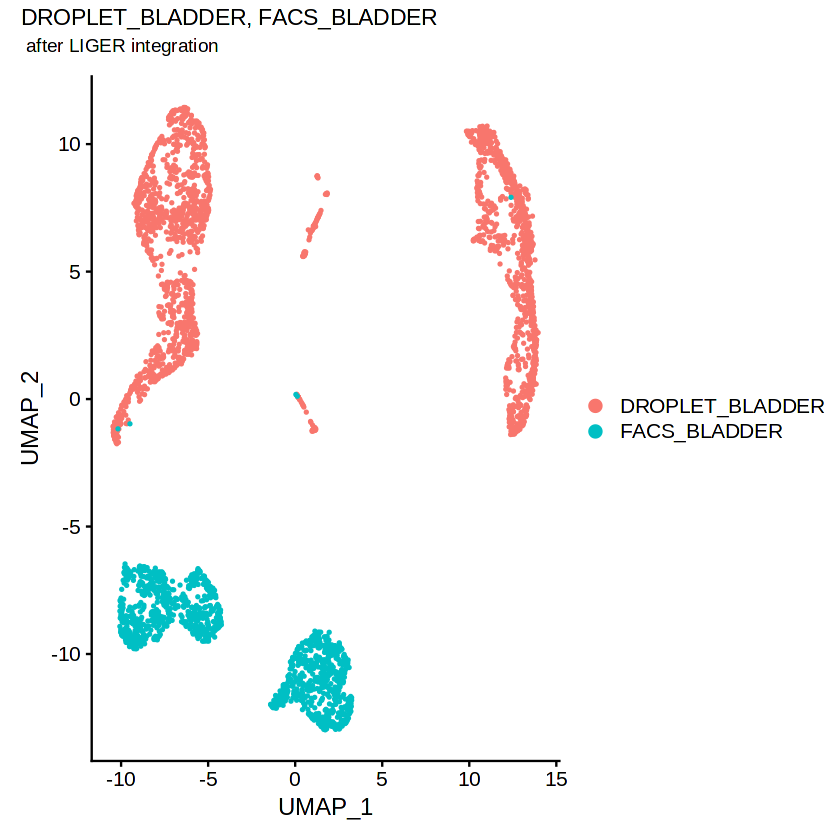

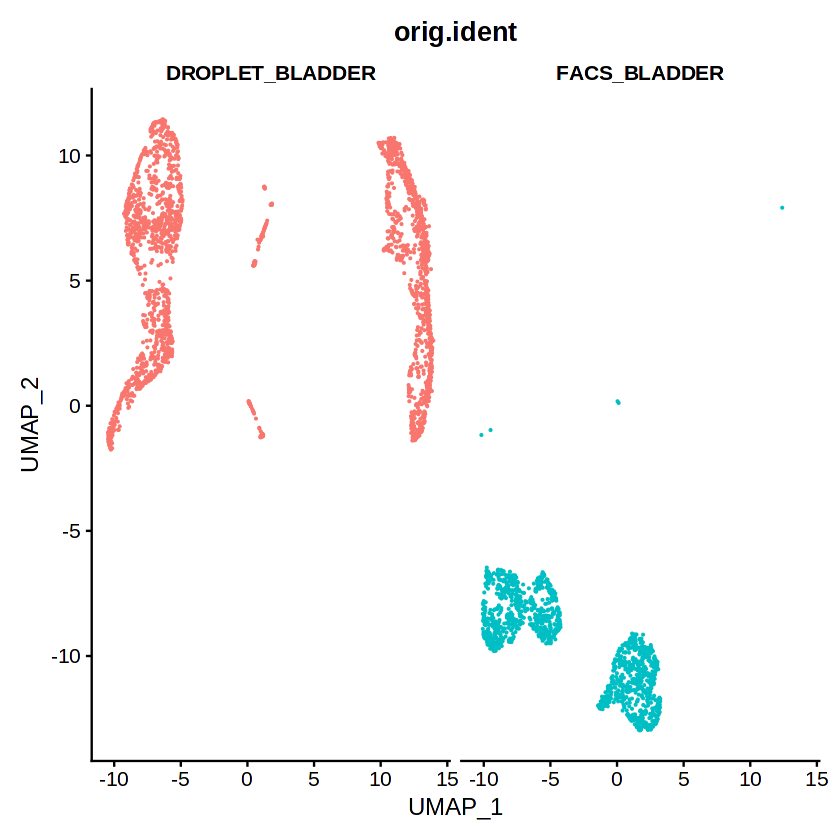

In [14]:
srat.liger <- RunUMAP(srat.liger, dims = 1:ncol(srat.liger[["inmf"]]), reduction = "inmf", verbose = F)
srat.liger <- SetIdent(srat.liger,value = batch_key)
DimPlot(srat.liger, reduction = "umap") + plot_annotation(title = paste(sapply(datasets, paste, collapse = ":"), collapse = ", "), " after LIGER integration")
DimPlot(srat.liger, reduction = "umap", group.by = batch_key, pt.size = .1, split.by = batch_key) + NoLegend()

In [2]:
input="/ps/ai-ready/data/error/droplet_Bladder_seurat_tiss.h5seurat"
output='/ps/ai-ready/data/Clustering/Tabula_Muris/droplet_Bladder_seurat_tiss.h5Seurat'
adata_path = '/ps/ai-ready/data/error/droplet_Bladder_seurat_tiss.h5ad'
unique_id='Seurat test'
assay='RNA'
min_genes=200
max_genes=0
min_UMI_count=0
max_UMI_count=0
percent_mt_max=5
percent_rb_min=0
resolution=0.5
dims=1:10
doublet_rate=0.075
regress_cell_cycle=FALSE

In [3]:
srat <- tryCatch(
        LoadSeurat(input),
        error = function(e) {
            # stop("The file format is not supported.")
            # print(e)
            RedisError(unique_id, paste0("The file format is not supported: ", e$message))
            stop(paste0("The file format is not supported: ", e$message))
        }
    )

[1] "Inside LoadSeurat"


Validating h5Seurat file

Initializing RNA with data

Adding counts for RNA

Adding miscellaneous information for RNA

Adding command information

Adding cell-level metadata

Adding miscellaneous information

Adding tool-specific results



In [4]:
srat

An object of class Seurat 
23341 features across 2500 samples within 1 assay 
Active assay: RNA (23341 features, 0 variable features)
 2 layers present: counts, data

In [5]:
srat <- NormalizeData(srat, normalization.method = "LogNormalize", scale.factor = 10000)

In [6]:
srat <- FindVariableFeatures(srat, selection.method = "vst", nfeatures = 2000)

In [7]:
srat

An object of class Seurat 
23341 features across 2500 samples within 1 assay 
Active assay: RNA (23341 features, 2000 variable features)
 2 layers present: counts, data

In [9]:
VariableFeatures(srat)

[1] "Cd74"          "H2-Aa"         "H2-Ab1"        "H2-Eb1"       
   [5] "Lyz2"          "Lyz1"          "C1qa"          "C1qb"         
   [9] "Il1b"          "C1qc"          "Apoe"          "Cd14"         
  [13] "Cd83"          "Sprr2f"        "Cxcl2"         "Tyrobp"       
  [17] "Sprr2g"        "Rn45s"         "Fcer1g"        "Ctss"         
  [21] "Rgs1"          "Ccl7"          "Cxcl10"        "Srgn"         
  [25] "Ccl9"          "Psca"          "Cd52"          "Ccl2"         
  [29] "Aqp1"          "Pf4"           "Ccl4"          "Cytip"        
  [33] "Fam25c"        "Cxcl1"         "Gm11428"       "Bcl2a1b"      
  [37] "Ccl3"          "Il33"          "Acta2"         "Mgl2"         
  [41] "Bcl2a1d"       "Cd209a"        "Ctla2a"        "Plvap"        
  [45] "Sprr2b"        "Rgs5"          "Cldn5"         "H2-DMb1"      
  [49] "Bglap2"        "Igfbp3"        "Coro1a"        "Stmn2"        
  [53] "Ccl6"          "Rrad"          "Pecam1"        "Retnla"       
  [57] "Emcn"          "Plbd1"         "Pcp4l1"        "Tm4sf1"       
  [61] "Clec3b"        "Gm13889"       "H2-DMa"        "Clec10a"      
  [65] "Slpi"          "Xist"          "Cdh5"          "Plek"         
  [69] "Vcam1"         "Egfl7"         "Slfn2"         "Fabp4"        
  [73] "Tnip3"         "Esam"          "Reg3g"         "Cenpf"        
  [77] "Apold1"        "Il6"           "Ms4a7"         "Hspa1a"       
  [81] "Ifit1"         "Rsad2"         "Aif1"          "Fcrls"        
  [85] "Scarb1"        "Alox5ap"       "Rasl11a"       "Ifit3"        
  [89] "Gclc"          "Slc7a11"       "A330069E16Rik" "Tagln"        
  [93] "Clu"           "Srxn1"         "Pi16"          "Fcgr3"        
  [97] "Tnfaip6"       "Gpr116"        "Gpihbp1"       "Laptm5"       
 [101] "C5ar1"         "Mmrn2"         "Napsa"         "Hist1h2ao"    
 [105] "Myh11"         "Agl"           "Tppp3"         "Eltd1"        
 [109] "Cfp"           "Upk3a"         "Mfap5"         "Ccr7"         
 [113] "Cox4i2"        "E030010A14Rik" "Lilrb4"        "Ppbp"         
 [117] "Rasd1"         "Csf1r"         "AA467197"      "Iigp1"        
 [121] "Emr1"          "Krt16"         "Dusp2"         "Cd93"         
 [125] "Flt1"          "Timp3"         "Ptx3"          "Lrg1"         
 [129] "Gja4"          "Ramp3"         "Sfpi1"         "Pln"          
 [133] "Upk2"          "Sncg"          "Mpeg1"         "Acer2"        
 [137] "Fgl2"          "Hmox1"         "Osm"           "Mrc1"         
 [141] "Robo4"         "Ly6k"          "Hsph1"         "Mef2c"        
 [145] "Samsn1"        "Isg15"         "Bcl2a1a"       "Gimap6"       
 [149] "Itgb7"         "C3ar1"         "Klf2"          "C130074G19Rik"
 [153] "Apoc1"         "Rac2"          "ORF63"         "Clec7a"       
 [157] "Ereg"          "2810417H13Rik" "Inmt"          "Ms4a6c"       
 [161] "Krt6a"         "Ifitm6"        "Ly86"          "Krt4"         
 [165] "Has1"          "Grrp1"         "Rgs16"         "Cxcl14"       
 [169] "Ptprb"         "Dpt"           "Aspn"          "Zfp935"       
 [173] "Ifi205"        "F830016B08Rik" "S100a4"        "Thrsp"        
 [177] "Tnfsf9"        "Ctgf"          "Csf2rb"        "Ly6c1"        
 [181] "Car3"          "Il10"          "Lum"           "Higd1b"       
 [185] "Hamp"          "Actg2"         "H2-Oa"         "Kdr"          
 [189] "Tnf"           "Des"           "Sdpr"          "AI607873"     
 [193] "Adm"           "Prss23"        "Ccr2"          "Pld4"         
 [197] "Upk1b"         "Cd53"          "Ccl11"         "S1pr1"        
 [201] "Nrip2"         "Rgs4"          "Cd34"          "Cyp1a1"       
 [205] "Postn"         "Pcdh17"        "Krt14"         "Cxcl9"        
 [209] "Cdca3"         "Rgs2"          "Podxl"         "Angptl7"      
 [213] "Rbp4"          "Cyp2f2"        "Cyr61"         "Krt20"        
 [217] "Sparcl1"       "Ccl12"         "Filip1l"       "Myl9"         
 [221] "Il1rn"         "Abcg2"         "Ube2c"         "Krtdap"       
 [225] "Nrp1"          "Mfa

In [10]:
srat@meta.data

,orig.ident,nCount_RNA,nFeature_RNA,channel,tissue,subtissue,mouse.sex,mouse.id,percent.ercc,percent.ribo,free_annotation,cell_ontology_class,res.0.4,previous_free_annotation,previous_cell_ontology_class,cluster.ids,cell_ontology_id
,<fct>,<dbl>,<int>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
10X_P4_3_AAAGTAGAGATGCCAG,10X,10291,2853,10X_P4_3,Bladder,,M,3-M-8,0,0.21960937,Bladder mesenchymal cell,bladder cell,0,NA,NA,0,CL:1001319
10X_P4_3_AACCGCGTCCAACCAA,10X,17520,4194,10X_P4_3,Bladder,,M,3-M-8,0,0.17671233,Bladder mesenchymal cell,bladder cell,2,NA,NA,2,CL:1001319
10X_P4_3_AACTCCCGTCGGGTCT,10X,12944,3347,10X_P4_3,Bladder,,M,3-M-8,0,0.19244438,Bladder mesenchymal cell,bladder cell,5,NA,NA,5,CL:1001319
10X_P4_3_AACTCTTAGTTGCAGG,10X,19594,3851,10X_P4_3,Bladder,,M,3-M-8,0,0.35638461,Luminal bladder epithelial cell,bladder urothelial cell,3,NA,NA,3,CL:1001428
10X_P4_3_AACTCTTTCATAACCG,10X,14594,3809,10X_P4_3,Bladder,,M,3-M-8,0,0.15711936,Bladder mesenchymal cell,bladder cell,2,NA,NA,2,CL:1001319
10X_P4_3_AAGACCTAGATCCGAG,10X,19190,3608,10X_P4_3,Bladder,,M,3-M-8,0,0.23778009,Monocyte/Macrophage,leukocyte,6,NA,NA,6,CL:0000738
10X_P4_3_AAGACCTAGGTGGGTT,10X,24484,4347,10X_P4_3,Bladder,,M,3-M-8,0,0.32809182,Basal bladder epithelial cell,bladder urothelial cell,1,NA,NA,1,CL:1001428
10X_P4_3_AAGGAGCGTGCAACTT,10X,5005,1960,10X_P4_3,Bladder,,M,3-M-8,0,0.19020979,Bladder mesenchymal cell,bladder cell,0,NA,NA,0,CL:1001319
10X_P4_3_AAGTCTGAGATAGTCA,10X,6253,2236,10X_P4_3,Bladder,,M,3-M-8,0,0.22597153,Luminal bladder epithelial cell,bladder urothelial cell,4,NA,NA,4,CL:1001428


In [12]:
srat[['RNA']]@meta.features

,vst.mean,vst.variance,vst.variance.expected,vst.variance.standardized,vst.variable
,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
Xkr4,0.0016,0.0015980792,0.0017496294,0.9133815,FALSE
Rp1,0.0004,0.0004000000,0.0004005521,0.9986216,FALSE
Sox17,0.0428,0.2546700280,0.0551756210,3.5306000,TRUE
Mrpl15,0.4000,0.4793917567,0.5880334304,0.8152458,FALSE
Lypla1,0.5512,0.7284699480,0.8741697112,0.8333278,FALSE
Tcea1,1.0472,1.5912086435,2.1291791708,0.7473343,FALSE
Rgs20,0.0008,0.0007996799,0.0008360070,0.9565468,FALSE
Atp6v1h,0.3992,0.5424563425,0.5865984707,0.9247490,FALSE
Oprk1,0.0060,0.0075670268,0.0072277315,1.0469435,FALSE


In [15]:
srat <- subset(srat, features=VariableFeatures(srat))
srat

An object of class Seurat 
2000 features across 2500 samples within 1 assay 
Active assay: RNA (2000 features, 2000 variable features)
 2 layers present: counts, data

In [4]:
info <- print(srat)
# RedisInfo(unique_id, info)

An object of class Seurat 
23341 features across 2500 samples within 1 assay 
Active assay: RNA (23341 features, 0 variable features)
 2 layers present: counts, data


In [ ]:
assay_names <- names(srat@assays)
        
if(length(assay_names)==1){
    assay <- DefaultAssay(srat) # If there is only one assay, then no matter if assay is provided, set assay to default assay
} else if (assay %in% assay_names){
    DefaultAssay(srat) <- assay # If there is more than one assay, and the user provides assay, then set default assay to assay
} 
default_assay <- DefaultAssay(srat)
RedisInfo(unique_id, paste0("Setting default_assay to ", default_assay))

if(IsNormalized(srat[[default_assay]]$counts, min_genes=min_genes)){
    RedisError(unique_id, "Seurat QC only takes raw counts, not normalized data.")
    stop("Seurat QC only takes raw counts, not normalized data.")
}

[1] 2

In [ ]:
local({
   load("/ps/ai-ready/data/Clustering/Tabula_Muris/droplet_Bladder_seurat_tiss.Robj")
   ls()
})

In [ ]:
name <- load("/ps/ai-ready/data/Clustering/Tabula_Muris/droplet_Bladder_seurat_tiss.Robj")

In [ ]:
get(name)

In [ ]:
tiss

In [ ]:
typeof(tiss)

In [ ]:
tiss_new <- UpdateSeuratObject(tiss)
tiss_new

In [ ]:
tiss_new

In [ ]:
tiss_new[['RNA']]@counts

In [ ]:
tiss_new@meta.data

In [ ]:
tiss_new@var.features

In [ ]:
srat <- load("/ps/ai-ready/data/Clustering/Tabula_Muris/droplet_Bladder_seurat_tiss.Robj")
srat

In [ ]:
dim(srat)

In [2]:
inupt_path <- "../../../oscb/user_storage/Benchmarks/facs-Bladder_1751302627486/QC/integration/SEURAT_integration.h5Seurat"

In [3]:
srat <- LoadSeurat(inupt_path)
srat

ERROR: Error in LoadSeurat(inupt_path): could not find function "LoadSeurat"


In [ ]:
names(srat@assays)

In [ ]:
'RNA' %in% names(srat@assays)

In [ ]:
DefaultAssay(srat)<-'SCT'

In [ ]:
names(srat@assays)

In [ ]:
DefaultAssay(srat)

In [ ]:
get_assays_from_seurat <- function(seurat_object) {
    assays_names <- 'RNA'

    if (DefaultAssay(seurat_object) != 'RNA') {
        assays_names <- names(srat@assays)
    }
    assays_names
}

In [ ]:
assays_names <- get_assays_from_seurat(srat)
assays_names

In [ ]:
SaveH5Seurat(srat, filename = "/ps/ai-ready/data/tung/tung1.h5Seurat", overwrite = TRUE, verbose = FALSE)

In [ ]:
seu = DietSeurat(
  srat,
  counts = TRUE, # so, raw counts save to adata.layers['counts']
  data = TRUE, # so, log1p counts save to adata.X when scale.data = False, else adata.layers['data']
  scale.data = FALSE, # if only scaled highly variable gene, the export to h5ad would fail. set to false
  features = rownames(srat), # export all genes, not just top highly variable genes
  assays = "RNA",
  dimreducs = c("pca","umap"),
  graphs = c("RNA_nn", "RNA_snn"), # to RNA_nn -> distances, RNA_snn -> connectivities
  misc = TRUE
)

In [ ]:
seu[['RNA']]@counts

In [ ]:
seu[['RNA']]

In [ ]:
path <- MuDataSeurat::WriteH5AD(seu, "/ps/ai-ready/data/tung/seu.h5ad", assay="RNA")
path

In [ ]:
DefaultAssay(srat)<-'SCT'

seu_sct = DietSeurat(
  srat,
  counts = TRUE, # so, raw counts save to adata.layers['counts']
  data = TRUE, # so, log1p counts save to adata.X when scale.data = False, else adata.layers['data']
  scale.data = FALSE, # if only scaled highly variable gene, the export to h5ad would fail. set to false
  features = rownames(srat), # export all genes, not just top highly variable genes
  assays = "SCT",
  dimreducs = c("pca","umap"),
  graphs = c("RNA_nn", "RNA_snn"), # to RNA_nn -> distances, RNA_snn -> connectivities
  misc = TRUE
)
seu_sct

In [ ]:
seu_sct[['SCT']]@counts

In [ ]:
DefaultAssay(seu_sct)<-'RNA'

In [ ]:
path <- "/ps/ai-ready/data/tung/umi.h5Seurat"
seurat_object <- LoadH5Seurat(path)
seurat_object

In [ ]:
DefaultAssay(seurat_object)

In [ ]:
path <- "/ps/ai-ready/data/tung/umi.h5Seurat"
results <- convert_seurat_to_anndata(path, assay = 'RNA')

In [ ]:
# inupt_path <- "/ps/ai-ready/data/filtered_gene_bc_matrices/hg19/"
# inupt_path <- "/ps/ai-ready/data/kbcfh/Anndata/hca_heart_neuronal_raw.h5ad"
# path_of_scrublet_calls<-"/ps/ai-ready/data/filtered_gene_bc_matrices/hg19/scrublet_calls.tsv"
inupt_path = "/ps/ai-ready/data/error/droplet_Bladder_seurat_tiss.h5seurat"

In [ ]:
srat <- LoadSeurat(inupt_path)
srat

In [ ]:
default_assay <- "RNA"

In [ ]:
if(!default_assay %in% names(x = srat)) stop(paste(default_assay, "does not exist."))
DefaultAssay(object = srat) <-default_assay

In [ ]:
head(srat[[]])

In [ ]:
srat[[default_assay]]@counts

In [ ]:
if(!paste0("nCount_", default_assay) %in% names(x = srat[[]])) srat[[paste0("nCount_", default_assay)]] <- colSums(x = srat[[default_assay]], slot = "counts")  # nCount of the default assay
if(!paste0("nFeature_", default_assay) %in% names(x = srat[[]])) srat[[paste0("nFeature_", default_assay)]] <- colSums(x = GetAssayData(object = srat[[default_assay]], slot = "counts") > 0)  # nFeature of the default assay

In [ ]:
meta <- srat@meta.data
dim(meta)
head(meta)

summary(meta[paste0("nCount_", default_assay)])
summary(meta[paste0("nFeature_", default_assay)])

In [ ]:
srat[["percent.mt"]] <- PercentageFeatureSet(srat, pattern = "^MT-") # Michochondrial genes
srat[["percent.rb"]] <- PercentageFeatureSet(srat, pattern = "^RP[SL]") # Ribosomal proteins (their names begin with RPS or RPL

In [ ]:
if(! "percent.hb" %in% names(x = srat[[]])) srat[["percent.hb"]] <- PercentageFeatureSet(srat, pattern = "^HB[^(P)]")
if(! "percent.plat" %in% names(x = srat[[]])) srat[["percent.plat"]] <- PercentageFeatureSet(srat, pattern = "PECAM1|PF4")

In [ ]:
# add the doublet annotation
doublets <- read.table(path_of_scrublet_calls, header = F, row.names = 1)
colnames(doublets) <- c("Doublet_score", "Is_doublet")
srat <- AddMetaData(srat, doublets)
head(srat[[]])

In [ ]:
names(srat[[]])

In [ ]:
srat[[]]["scrublet_score"]

In [ ]:
doublets

In [ ]:
VlnPlot(srat, features = c(paste0("nFeature_", default_assay), paste0("nCount_", default_assay),"percent.mt","percent.rb"),ncol = 4,pt.size = 0.1) & 
  theme(plot.title = element_text(size=10))

In [ ]:
FeatureScatter(srat, feature1 = paste0("nCount_", default_assay), feature2 = "percent.mt")
FeatureScatter(srat, feature1 = paste0("nCount_", default_assay), feature2 = paste0("nFeature_", default_assay))
FeatureScatter(srat, feature1 = paste0("nCount_", default_assay), feature2 = "percent.rb")
FeatureScatter(srat, feature1 = "percent.rb", feature2 = "percent.mt")
# FeatureScatter(srat, feature1 = paste0("nFeature_", default_assay), feature2 = "Doublet_score")
FeatureScatter(srat, feature1 = paste0("nFeature_", default_assay), feature2 = "scrublet_score")

In [ ]:
srat[['QC']] <- ifelse(srat@meta.data$Is_doublet == 'True','Doublet','Pass')
srat[['QC']] <- ifelse(srat@meta.data[paste0("nFeature_", default_assay)] < 500 & srat@meta.data$QC == 'Pass','Low_nFeature',srat@meta.data$QC)
srat[['QC']] <- ifelse(srat@meta.data[paste0("nFeature_", default_assay)] < 500 & srat@meta.data$QC != 'Pass' & srat@meta.data$QC != 'Low_nFeature',paste('Low_nFeature',srat@meta.data$QC,sep = ','),srat@meta.data$QC)
srat[['QC']] <- ifelse(srat@meta.data$percent.mt > 15 & srat@meta.data$QC == 'Pass','High_MT',srat@meta.data$QC)
srat[['QC']] <- ifelse(srat@meta.data[paste0("nFeature_", default_assay)] < 500 & srat@meta.data$QC != 'Pass' & srat@meta.data$QC != 'High_MT',paste('High_MT',srat@meta.data$QC,sep = ','),srat@meta.data$QC)
table(srat[['QC']])

In [ ]:
srat[[]]

In [ ]:
VlnPlot(srat, features = c("nFeature_RNA","nCount_RNA","percent.mt","percent.rb"),ncol = 4,pt.size = 0.1) & 
  theme(plot.title = element_text(size=10))

In [ ]:
FeatureScatter(srat, feature1 = "nCount_RNA", feature2 = "percent.mt")
FeatureScatter(srat, feature1 = "nCount_RNA", feature2 = "nFeature_RNA")
FeatureScatter(srat, feature1 = "nCount_RNA", feature2 = "percent.rb")
FeatureScatter(srat, feature1 = "percent.rb", feature2 = "percent.mt")
FeatureScatter(srat, feature1 = "nFeature_RNA", feature2 = "Doublet_score")

In [ ]:
srat[['QC']] <- ifelse(srat@meta.data$Is_doublet == 'True','Doublet','Pass')
srat[['QC']] <- ifelse(srat@meta.data$nFeature_RNA < 500 & srat@meta.data$QC == 'Pass','Low_nFeature',srat@meta.data$QC)
srat[['QC']] <- ifelse(srat@meta.data$nFeature_RNA < 500 & srat@meta.data$QC != 'Pass' & srat@meta.data$QC != 'Low_nFeature',paste('Low_nFeature',srat@meta.data$QC,sep = ','),srat@meta.data$QC)
srat[['QC']] <- ifelse(srat@meta.data$percent.mt > 15 & srat@meta.data$QC == 'Pass','High_MT',srat@meta.data$QC)
srat[['QC']] <- ifelse(srat@meta.data$nFeature_RNA < 500 & srat@meta.data$QC != 'Pass' & srat@meta.data$QC != 'High_MT',paste('High_MT',srat@meta.data$QC,sep = ','),srat@meta.data$QC)
table(srat[['QC']])

In [ ]:
srat[['QC']]

In [ ]:
VlnPlot(subset(srat, subset = QC == 'Pass'), 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt","percent.rb"), ncol = 4, pt.size = 0.1) & 
  theme(plot.title = element_text(size=10))